# 심층 상관관계 EDA (느린 분석 포함)

이 노트북은 **원시 `train.csv` 숫자 피처**만 사용합니다 (베이스라인 전처리 전).  
목적은 “**서로 얼마나 같이 움직이는지**”와 “**사기 여부와 어떤 관계인지**”를 여러 각도에서 보는 것입니다.

---

## 이 문서에서 쓰는 말 뜻

| 용어 | 의미 |
|------|------|
| **Pearson r** | 두 변수가 **직선**으로 얼마나 함께 변하는지 (−1~1). 이상치에 민감. |
| **Spearman ρ** | 값을 **순위**로 바꾼 뒤 Pearson과 같은 식. **단조 증가/감소** 관계에 강하고, 이상치에 덜 민감. |
| **상관 행렬** | 모든 숫자 피처 쌍의 r 또는 ρ를 한 표로 모은 것. |
| **Clustermap** | 상관 행렬을 **계층적 군집**으로 행·열 순서를 바꿔, 비슷한 패턴의 변수가 **한 덩어리**로 보이게 한 히트맵. |
| **Mutual Information (MI)** | 선형이 아니어도 **의존성(정보 공유)** 크기를 0 이상으로 측정. 타깃이 이진일 때 피처의 “유용도” 참고용. |
| **부트스트랩 CI** | 데이터를 반복 재표집해 **상관계수의 불확실 구간**(대략 95%)을 보는 것. |

---

## 섹션 안내 (아래 순서대로)

1. **피처 간 Spearman / Pearson 행렬** — 전체 쌍의 선형·순위 관계.
2. **Clustermap** — 변수 덩어리(다중공선성 후보) 시각화.
3. **타깃과의 상관** — 사기와 연관된 피처 순위, Pearson vs Spearman 비교.
4. **강한 피처 쌍** — \|ρ\|가 큰 쌍 목록 (CSV).
5. **상위 K 피처 부분 히트맵** — 읽기 쉬운 확대.
6. **Mutual Information** — (느림) 비선형 의존성 보조 지표.
7. **부트스트랩 CI** — (느림) 타깃–피처 Spearman의 구간 추정.
8. **Pairplot** — (느림) 상위 피처 몇 개의 산점도 격자.
9. **상관 네트워크** — (선택) 강한 쌍을 그래프로.
10. **나이 × 연간소득 / 거주 / 고용** — `age_bucket`과 `yearly_income`, `housing_status`, `employment_status` 교차·검정·시각화 (원시 범주형 포함).
11. **나이 × 전체 피처** — 요약 CSV + `age×각 피처` **§10형 누적 막대**(선택) + **모든 피처 쌍 (P,G)** 에 대해 `P×G` 누적 막대(`age×G`와 동일 로직). 기본 **표본**(`AGE11_MAX_ROWS`).

산출물은 **`eda_corr_output/`** 에 저장됩니다.

---

## 속도 조절

- 맨 위 코드 셀의 **`SAMPLE_N`**: `None`이면 **전체 행** (상관 계산·클러스터맵에 시간·RAM 많이 듦). 빠르게 보려면 `250_000` 등으로 줄이세요.
- **§6~§8** 은 추가로 오래 걸리도록 설계했습니다 (`MI_MAX_ROWS`, `BOOTSTRAP_B`, `PAIRPLOT_SAMPLE` 등).

In [3]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
np.random.seed(SEED)

# None이면 전체 행으로 상관 계산 (느리지만 가장 ‘확실’). 숫자면 층화 샘플.
SAMPLE_N = None

OUT_DIR = "eda_corr_output"
os.makedirs(OUT_DIR, exist_ok=True)

TARGET = "fraud_bool"
DROP_FROM_PAIRWISE = {"id", TARGET}

# --- 느린 섹션용 (None이면 아래에서 X 전체/대부분 사용) ---
MI_MAX_ROWS = 1_000_000  # Mutual Information 계산에 쓸 최대 행 수
BOOTSTRAP_B = 120  # 타깃-Spearman 부트스트랩 반복 (많을수록 느림)
BOOTSTRAP_SUB = 80_000  # 부트스트랩 한 번당 표본 행 수
PAIRPLOT_SAMPLE = 5_000  # Pairplot stratified 표본
PAIRPLOT_FEATS = 5  # Pairplot에 넣을 피처 개수 (6 이상이면 매우 느려짐)
CORR_NET_THR = 0.45  # 네트워크에 그릴 최소 |Spearman|

print("저장 폴더:", os.path.abspath(OUT_DIR))

저장 폴더: c:\Users\antt6\Desktop\쿠아이 데이터톤\eda_corr_output


In [4]:
train = pd.read_csv("train.csv")

if SAMPLE_N is not None and len(train) > SAMPLE_N:
    train, _ = train_test_split(
        train,
        train_size=SAMPLE_N,
        stratify=train[TARGET],
        random_state=SEED,
    )

num_cols = [
    c
    for c in train.select_dtypes(include=[np.number]).columns
    if c not in DROP_FROM_PAIRWISE
]

X = train[num_cols].replace(-1, np.nan)
X = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X),
    columns=num_cols,
    index=train.index,
)
y = train[TARGET].astype(np.float64)

print("행 수:", len(train), "| 숫자 피처 수:", len(num_cols))
print("사기 비율:", f"{y.mean():.4%}")

행 수: 700000 | 숫자 피처 수: 26
사기 비율: 1.0917%


## 1) Spearman / Pearson 상관 행렬 (피처 간)

**무엇을 하나요?**  
모든 숫자 피처 쌍에 대해 **Spearman**과 **Pearson** 상관행렬을 각각 만듭니다.

**왜 보나요?**  
- 두 행렬을 **나란히 저장**해 두면, 나중에 “선형만 보는지 / 순위까지 보는지”를 비교할 수 있습니다.  
- 상수에 가까운 열은 상관이 정의되지 않아 NaN이 날 수 있어, 이후 클러스터링용으로 **정리(대각 1, NaN→0)** 합니다.

**시간:** 행이 많을수록 `DataFrame.corr()` 비용이 커집니다 (`SAMPLE_N`으로 조절).

다음 코드 셀 실행 후 CSV 두 개가 `eda_corr_output/` 에 저장됩니다.

In [5]:
def _corr_clean(df, method):
    c = df.corr(method=method, min_periods=3)
    # pandas 2.x 배열이 read-only일 수 있어 복사 후 정리
    arr = np.array(c.values, dtype=np.float64, copy=True, order="C")
    np.fill_diagonal(arr, 1.0)
    out = pd.DataFrame(arr, index=c.index, columns=c.columns)
    return out.fillna(0.0)


t0 = time.perf_counter()
corr_s = _corr_clean(X, "spearman")
t1 = time.perf_counter()
corr_p = _corr_clean(X, "pearson")
t2 = time.perf_counter()
print(f"Spearman: {t1 - t0:.1f}s | Pearson: {t2 - t1:.1f}s")

corr_s.to_csv(os.path.join(OUT_DIR, "corr_spearman_features.csv"))
corr_p.to_csv(os.path.join(OUT_DIR, "corr_pearson_features.csv"))
print("CSV 저장: corr_spearman_features.csv, corr_pearson_features.csv")

KeyboardInterrupt: 

## 2) 계층적 클러스터링 히트맵 (Clustermap)

**무엇을 하나요?**  
§1에서 만든 상관행렬을 입력으로, **변수 간 “거리”**를 정해 **덴드로그램**을 만든 뒤, 비슷한 변수가 가까이 오도록 행·열을 재배열한 큰 히트맵을 그립니다.

**왜 보나요?**  
- 단순 히트맵은 변수 순서가 CSV 컬럼 순이라 **패턴이 안 보일** 수 있습니다.  
- 클러스터링 후에는 **함께 움직이는 변수 묶음**(다중공선성·파생 규칙 후보)이 눈에 들어옵니다.

**시간:** 행렬 크기 \(p×p\)에 대해 \(O(p^3)\)에 가까운 링크 연산이 들어가 **피처 수가 많으면** 오래 걸립니다.

출력: `clustermap_spearman.png`, `clustermap_pearson.png`

In [ ]:
def save_clustermap(corr, title, fname, figsize=(14, 14)):
    g = sns.clustermap(
        corr,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        figsize=figsize,
        dendrogram_ratio=0.12,
        cbar_pos=(0.02, 0.8, 0.03, 0.15),
        xticklabels=True,
        yticklabels=True,
    )
    g.fig.suptitle(title, y=1.02, fontsize=13)
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, fontsize=7)
    plt.setp(g.ax_heatmap.get_yticklabels(), fontsize=7)
    out = os.path.join(OUT_DIR, fname)
    g.savefig(out, dpi=150, bbox_inches="tight")
    plt.close()
    print("저장:", out)


save_clustermap(corr_s, "Spearman correlation (clustered)", "clustermap_spearman.png")
save_clustermap(corr_p, "Pearson correlation (clustered)", "clustermap_pearson.png")

저장: eda_corr_output\clustermap_spearman.png
저장: eda_corr_output\clustermap_pearson.png


## 3) 타깃(`fraud_bool`)과의 상관 — 전체 피처

**무엇을 하나요?**  
각 숫자 피처와 `fraud_bool` 사이의 **Spearman ρ**와 **Pearson r**을 한 번에 계산합니다 (`corrwith`).

**왜 보나요?**  
- **단변량**으로 “이 피처만 봤을 때 사기와 연관이 있는가?”의 순위를 만듭니다.  
- **Spearman vs Pearson** 산점도: 선형에 가까우면 두 값이 비슷하고, 순위만 맞으면 Spearman만 클 수 있습니다.

**해석:** 이진 타깃과의 Pearson r은 **점이설 상관**과 같은 맥락으로 읽는 경우가 많습니다 (연속 피처가 정규에 가깝다는 가정은 약함).

출력: `corr_with_target_fraud_bool.csv`, `bar_target_top30.png`, `scatter_pearson_vs_spearman_target.png`

In [ ]:
t0 = time.perf_counter()
tgt_s = X.corrwith(y, method="spearman")
tgt_p = X.corrwith(y, method="pearson")
print(f"타깃 상관 계산: {time.perf_counter() - t0:.1f}s")

tgt_s.name = "spearman"
tgt_p.name = "pearson"
tgt_df = pd.concat([tgt_s, tgt_p], axis=1)
tgt_df = tgt_df.dropna(how="any")
tgt_df["abs_spearman"] = tgt_df["spearman"].abs()
tgt_df = tgt_df.sort_values("abs_spearman", ascending=False)
tgt_df.to_csv(os.path.join(OUT_DIR, "corr_with_target_fraud_bool.csv"))
print("저장: corr_with_target_fraud_bool.csv")
display(tgt_df.head(20))

타깃 상관 계산: 5.0s
저장: corr_with_target_fraud_bool.csv


,spearman,pearson,abs_spearman
credit_risk_score,0.059563,0.069889,0.059563
age_bucket,0.057255,0.062126,0.057255
req_credit_limit,0.057039,0.068466,0.057039
is_session_persistent,-0.050094,-0.050094,0.050094
yearly_income,0.048533,0.043939,0.048533
curr_addr_months,0.048459,0.033720,0.048459
dob_email_count_4w,-0.044972,-0.042397,0.044972
name_email_sim,-0.037038,-0.036477,0.037038
device_email_cnt_8w,0.036659,0.036439,0.036659
has_other_cards,-0.035578,-0.035578,0.035578


C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\1792897760.py:9: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\1792897760.py:9: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\1792897760.py:9: UserWarning: Glyph 53440 (\N{HANGUL SYLLABLE TA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\1792897760.py:9: UserWarning: Glyph 44611 (\N{HANGUL SYLLABLE GIS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\1792897760.py:9: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\1792897760.py:9: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) Arial.
  plt.tight_layout

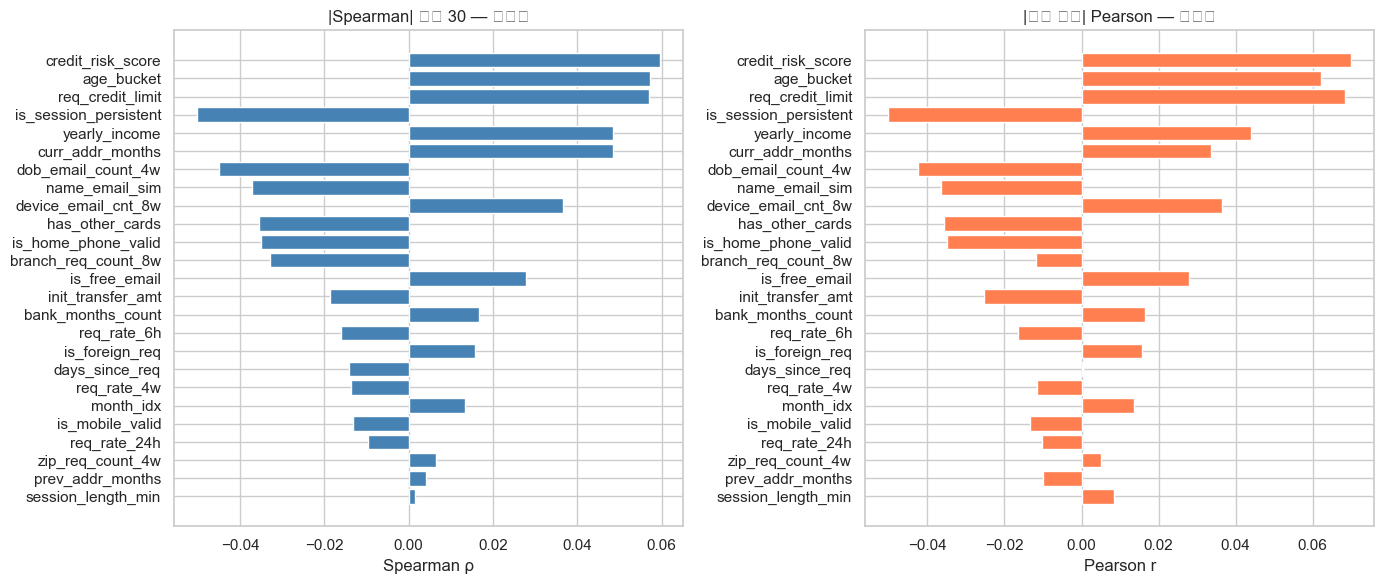

저장: eda_corr_output\bar_target_top30.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top = tgt_df.head(30)
axes[0].barh(top.index[::-1], top["spearman"].values[::-1], color="steelblue")
axes[0].set_title("|Spearman| 상위 30 — 타깃과")
axes[0].set_xlabel("Spearman ρ")
axes[1].barh(top.index[::-1], top["pearson"].values[::-1], color="coral")
axes[1].set_title("|정렬 동일| Pearson — 타깃과")
axes[1].set_xlabel("Pearson r")
plt.tight_layout()
fp = os.path.join(OUT_DIR, "bar_target_top30.png")
fig.savefig(fp, dpi=150, bbox_inches="tight")
plt.show()
print("저장:", fp)

C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\2697709040.py:10: UserWarning: Glyph 54588 (\N{HANGUL SYLLABLE PI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\2697709040.py:10: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\2697709040.py:10: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\2697709040.py:10: UserWarning: Glyph 53440 (\N{HANGUL SYLLABLE TA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\2697709040.py:10: UserWarning: Glyph 44611 (\N{HANGUL SYLLABLE GIS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\2697709040.py:10: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) Arial.
  plt.tight_l

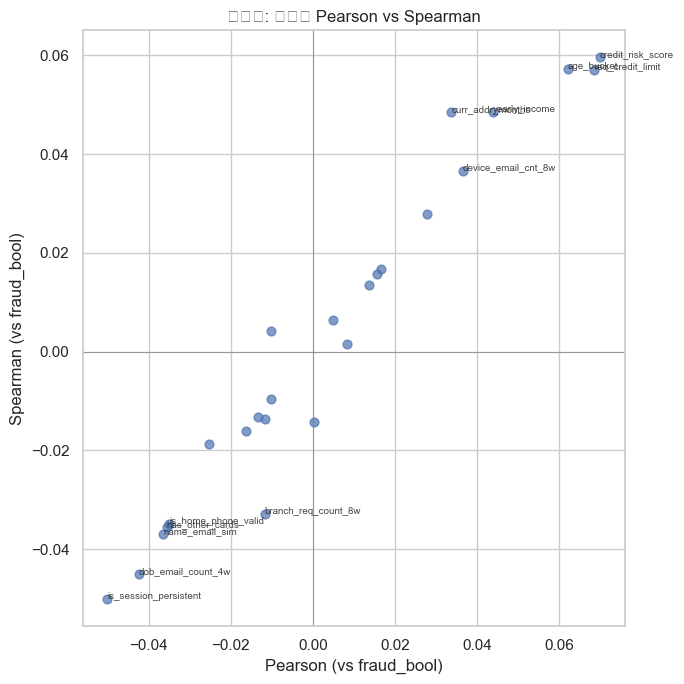

저장: eda_corr_output\scatter_pearson_vs_spearman_target.png


In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(tgt_df["pearson"], tgt_df["spearman"], alpha=0.7, s=40)
for i, row in tgt_df.head(12).iterrows():
    ax.annotate(i, (row["pearson"], row["spearman"]), fontsize=7, alpha=0.85)
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel("Pearson (vs fraud_bool)")
ax.set_ylabel("Spearman (vs fraud_bool)")
ax.set_title("피처별: 타깃과 Pearson vs Spearman")
plt.tight_layout()
fp = os.path.join(OUT_DIR, "scatter_pearson_vs_spearman_target.png")
fig.savefig(fp, dpi=150, bbox_inches="tight")
plt.show()
print("저장:", fp)

## 4) 피처 간 ‘강한’ 상관 쌍 (Spearman)

**무엇을 하나요?**  
Spearman 행렬의 **상삼각**만 돌며, \|ρ\|이 임계값 `MIN_ABS` 이상인 **피처 쌍**을 모아 표로 저장합니다.

**왜 보나요?**  
- 두 피처가 매우 강하게 상관하면 **한쪽만 남겨도** 되는 후보가 됩니다.  
- 나중에 파생 변수를 만들 때 **같은 정보를 두 번 넣는지** 점검합니다.

출력: `strong_pairwise_spearman.csv` (`MIN_ABS`는 코드 셀에서 변경)

In [ ]:
MIN_ABS = 0.25
pairs = []
cols = corr_s.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        a, b = cols[i], cols[j]
        rho = corr_s.iloc[i, j]
        if abs(rho) >= MIN_ABS:
            pairs.append((a, b, rho))
pair_df = pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman_rho"])
pair_df["abs_rho"] = pair_df["spearman_rho"].abs()
pair_df = pair_df.sort_values("abs_rho", ascending=False)
pair_df.to_csv(os.path.join(OUT_DIR, "strong_pairwise_spearman.csv"), index=False)
print(f"|ρ| ≥ {MIN_ABS} 인 쌍: {len(pair_df)}개")
display(pair_df.head(40))

|ρ| ≥ 0.25 인 쌍: 11개


,feature_a,feature_b,spearman_rho,abs_rho
8,req_rate_4w,month_idx,-0.853428,0.853428
9,credit_risk_score,req_credit_limit,0.631493,0.631493
7,req_rate_24h,month_idx,-0.554846,0.554846
6,req_rate_24h,req_rate_4w,0.546116,0.546116
3,req_rate_6h,req_rate_24h,0.473427,0.473427
0,age_bucket,dob_email_count_4w,-0.441646,0.441646
5,req_rate_6h,month_idx,-0.413600,0.413600
4,req_rate_6h,req_rate_4w,0.404985,0.404985
1,zip_req_count_4w,req_rate_4w,0.293376,0.293376
2,zip_req_count_4w,month_idx,-0.288015,0.288015


## 5) 타깃 상관 상위 K개만 확대 히트맵 (가독성)

**무엇을 하나요?**  
§3에서 \|Spearman\| 기준 상위 **K개** 피처만 골라, 그 피처들 **끼리**의 Spearman 부분 행렬을 히트맵으로 그립니다.

**왜 보나요?**  
- 전체 클러스터맵은 피처가 많으면 **글자가 작아** 해석이 어렵습니다.  
- 상위 피처들 사이에 **또 다른 강한 상관**이 있는지 집중해서 봅니다.

`TOP_K`는 아래 코드 셀에서 조절합니다.  
출력: `heatmap_top{K}_spearman_submatrix.png`

C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\35513262.py:17: UserWarning: Glyph 53440 (\N{HANGUL SYLLABLE TA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\35513262.py:17: UserWarning: Glyph 44611 (\N{HANGUL SYLLABLE GIS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\35513262.py:17: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\35513262.py:17: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\35513262.py:17: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\antt6\AppData\Local\Temp\ipykernel_21056\35513262.py:17: UserWarning: Glyph 54588 (\N{HANGUL SYLLABLE PI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Us

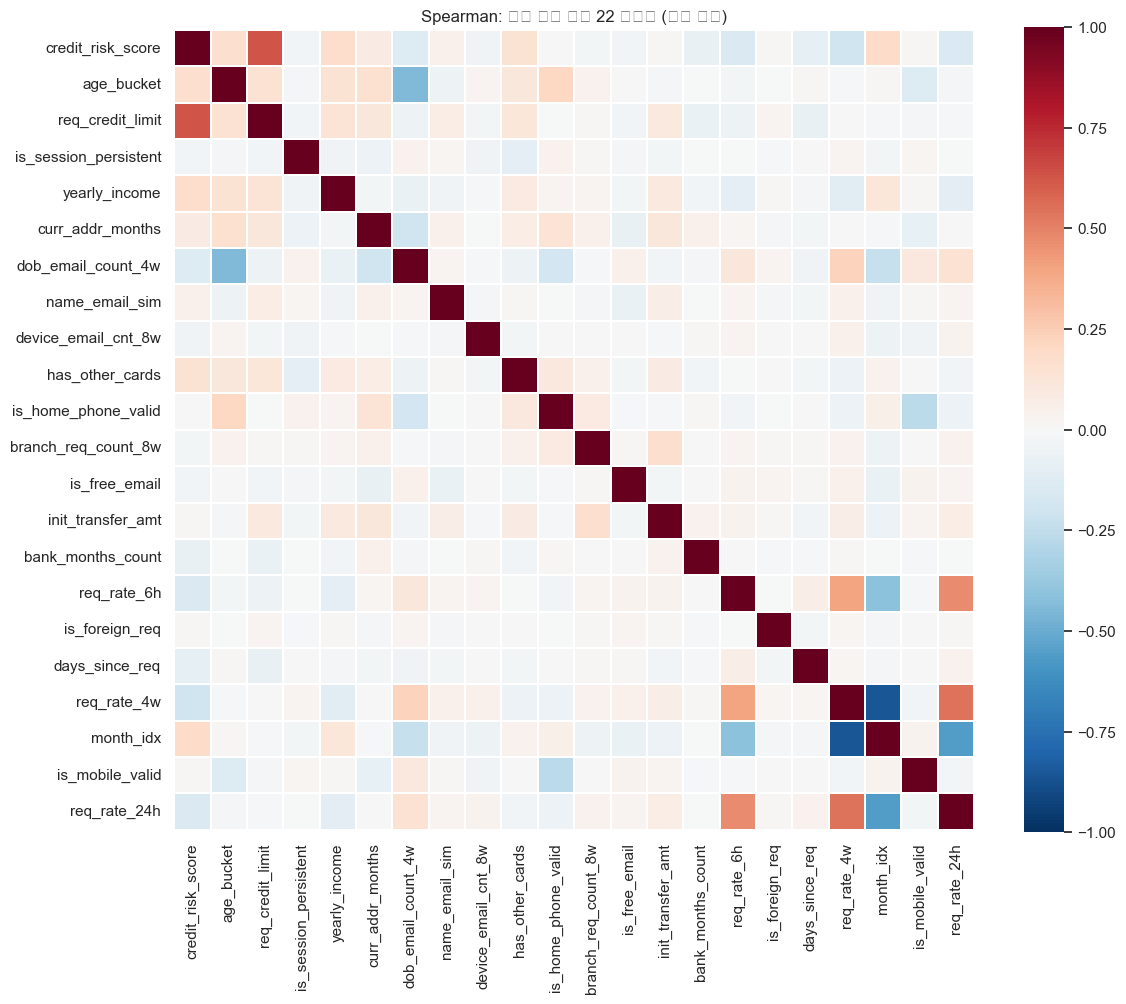

저장: eda_corr_output\heatmap_top22_spearman_submatrix.png


In [ ]:
TOP_K = 22
top_feat = tgt_df.index[:TOP_K].tolist()
sub = corr_s.loc[top_feat, top_feat]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    sub,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
    linewidths=0.3,
)
ax.set_title(f"Spearman: 타깃 상관 상위 {TOP_K} 피처만 (서브 행렬)")
plt.tight_layout()
fp = os.path.join(OUT_DIR, f"heatmap_top{TOP_K}_spearman_submatrix.png")
fig.savefig(fp, dpi=150, bbox_inches="tight")
plt.show()
print("저장:", fp)

## 6) Mutual Information (타깃과의 비선형 의존성) — **느림**

**무엇을 하나요?**  
`sklearn.feature_selection.mutual_info_classif`로 각 숫자 피처와 `fraud_bool` 사이의 **정보 이득**(0 이상, 클수록 의존성 큼)을 추정합니다. **선형이 아닌** 관계도 일부 잡아냅니다.

**왜 보나요?**  
Spearman/Pearson은 **단조·선형**에 가깝게 요약합니다. MI는 다른 가정으로 **보조 순위**를 줍니다 (해석은 “절대값의 크기”보다 **상대 순위** 위주가 안전).

**시간:** `MI_MAX_ROWS`만큼만 사용합니다. 늘리면 **몇 분~수십 분**까지 갈 수 있습니다.

출력: `mutual_info_target.csv`, `bar_mutual_info_top30.png`

MI 계산 (700,000행): 119.4s


device_email_cnt_8w      0.076647
is_session_persistent    0.071527
is_mobile_valid          0.064733
is_free_email            0.063844
is_home_phone_valid      0.042316
prev_addr_months         0.026068
req_credit_limit         0.020025
age_bucket               0.019466
yearly_income            0.013109
has_other_cards          0.012127
bank_months_count        0.010910
month_idx                0.009029
dob_email_count_4w       0.005339
credit_risk_score        0.002871
curr_addr_months         0.001999
name_email_sim           0.000938
branch_req_count_8w      0.000802
init_transfer_amt        0.000688
days_since_req           0.000432
is_foreign_req           0.000407
Name: mutual_info, dtype: float64

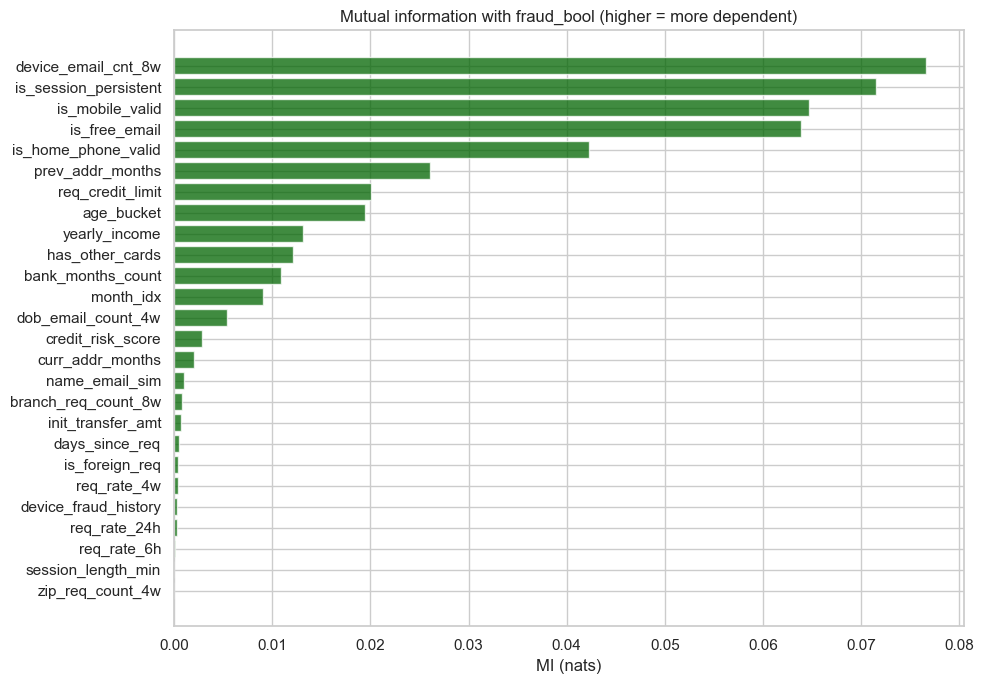

저장: eda_corr_output\bar_mutual_info_top30.png


In [ ]:
t0 = time.perf_counter()
Xm = X
ym = y
if MI_MAX_ROWS is not None and len(Xm) > MI_MAX_ROWS:
    Xm, ym = train_test_split(
        Xm,
        ym,
        train_size=MI_MAX_ROWS,
        stratify=ym.astype(int),
        random_state=SEED,
    )
mi = mutual_info_classif(
    Xm.values,
    ym.values.astype(int),
    discrete_features=False,
    random_state=SEED,
    n_neighbors=5,
)
mi_s = pd.Series(mi, index=num_cols, name="mutual_info").sort_values(ascending=False)
mi_s.to_csv(os.path.join(OUT_DIR, "mutual_info_target.csv"), header=True)
print(f"MI 계산 ({len(Xm):,}행): {time.perf_counter() - t0:.1f}s")
display(mi_s.head(20))

fig, ax = plt.subplots(figsize=(10, 7))
topm = mi_s.head(30)
ax.barh(topm.index[::-1], topm.values[::-1], color="darkgreen", alpha=0.75)
ax.set_title("Mutual information with fraud_bool (higher = more dependent)")
ax.set_xlabel("MI (nats)")
plt.tight_layout()
fp = os.path.join(OUT_DIR, "bar_mutual_info_top30.png")
fig.savefig(fp, dpi=150, bbox_inches="tight")
plt.show()
print("저장:", fp)

## 7) 부트스트랩 — 타깃 Spearman의 95% 구간 (느림)

**무엇을 하나요?**  
타깃과의 Spearman이 상위인 피처 **TOP_N_BOOT**개를 골라, 데이터를 **복원 추출**로 `BOOTSTRAP_B`번 반복하며 매번 표본 크기 `BOOTSTRAP_SUB`로 ρ를 다시 계산합니다. 2.5~97.5% 분위로 **대략 95% 구간**을 만듭니다.

**왜 보나요?**  
한 번 계산한 ρ는 **표본 오차**가 있습니다. 구간이 넓으면 “데이터가 조금만 바뀌어도 순위가 바뀔 수 있다”는 뜻입니다.

**시간:** `BOOTSTRAP_B × BOOTSTRAP_SUB`에 비례해 길어집니다.

출력: `bootstrap_spearman_target_ci.csv`

부트스트랩 완료: 16.2s


,feature,spearman_full_sample,boot_mean_rho,boot_ci_low,boot_ci_high
0,credit_risk_score,0.059563,0.059654,0.051605,0.067517
1,age_bucket,0.057255,0.057604,0.049846,0.064495
2,req_credit_limit,0.057039,0.057404,0.049661,0.064592
3,is_session_persistent,-0.050094,-0.050246,-0.055772,-0.044277
5,curr_addr_months,0.048459,0.048731,0.043169,0.054142
4,yearly_income,0.048533,0.048430,0.040051,0.055732
6,dob_email_count_4w,-0.044972,-0.045316,-0.052329,-0.037531
7,name_email_sim,-0.037038,-0.037157,-0.043976,-0.030048
8,device_email_cnt_8w,0.036659,0.036883,0.026919,0.046985
9,has_other_cards,-0.035578,-0.035605,-0.040065,-0.030455


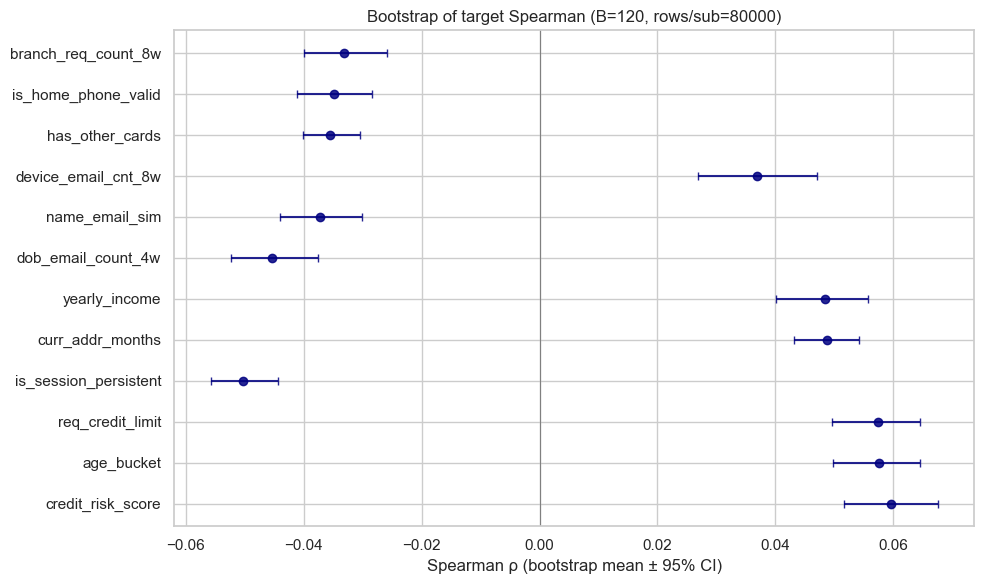

저장: eda_corr_output\bootstrap_spearman_ci_errorbar.png


In [ ]:
TOP_N_BOOT = 12
rng = np.random.default_rng(SEED)
top_cols = tgt_df.head(TOP_N_BOOT).index.tolist()
n = len(X)
boot_rho = {c: [] for c in top_cols}

t0 = time.perf_counter()
for _ in range(BOOTSTRAP_B):
    idx = rng.choice(n, size=min(BOOTSTRAP_SUB, n), replace=True)
    xs = X.iloc[idx]
    ys = y.iloc[idx]
    for c in top_cols:
        rho, _ = spearmanr(xs[c].values, ys.values)
        boot_rho[c].append(rho)

rows = []
for c in top_cols:
    arr = np.array(boot_rho[c])
    lo, hi = np.percentile(arr, [2.5, 97.5])
    rows.append(
        {
            "feature": c,
            "spearman_full_sample": float(tgt_df.loc[c, "spearman"]),
            "boot_mean_rho": float(np.mean(arr)),
            "boot_ci_low": float(lo),
            "boot_ci_high": float(hi),
        }
    )
boot_df = pd.DataFrame(rows)
boot_df["_abs"] = boot_df["boot_mean_rho"].abs()
boot_df = boot_df.sort_values("_abs", ascending=False).drop(columns=["_abs"])

boot_df.to_csv(os.path.join(OUT_DIR, "bootstrap_spearman_target_ci.csv"), index=False)
print(f"부트스트랩 완료: {time.perf_counter() - t0:.1f}s")
display(boot_df)

fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(boot_df))
x = boot_df["boot_mean_rho"].values
xerr = np.vstack([x - boot_df["boot_ci_low"].values, boot_df["boot_ci_high"].values - x])
ax.errorbar(x, y_pos, xerr=xerr, fmt="o", capsize=3, color="navy", alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(boot_df["feature"])
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Spearman ρ (bootstrap mean ± 95% CI)")
ax.set_title(f"Bootstrap of target Spearman (B={BOOTSTRAP_B}, rows/sub={BOOTSTRAP_SUB})")
plt.tight_layout()
fp = os.path.join(OUT_DIR, "bootstrap_spearman_ci_errorbar.png")
fig.savefig(fp, dpi=150, bbox_inches="tight")
plt.show()
print("저장:", fp)

## 8) Pairplot (상위 피처 산점도 격자) — **매우 느림**

**무엇을 하나요?**  
타깃 Spearman 상위 `PAIRPLOT_FEATS`개 피처를 고르고, **층화 추출**한 `PAIRPLOT_SAMPLE`행만 사용해 `sns.pairplot`으로 **모든 쌍**의 산점도를 한 번에 그립니다. 색은 정상/사기로 구분합니다.

**왜 보나요?**  
상관계수만으로는 **비선형·이상치·클러스터**가 안 보일 수 있습니다. Pairplot은 “같이 선형인지”를 눈으로 검증합니다.

**시간:** 피처 수 \(k\)에 대해 부분 플롯 수는 \(k(k-1)/2\) 이라 **k를 5~6 이상** 올리면 매우 느려집니다.

출력: `pairplot_top_features.png`

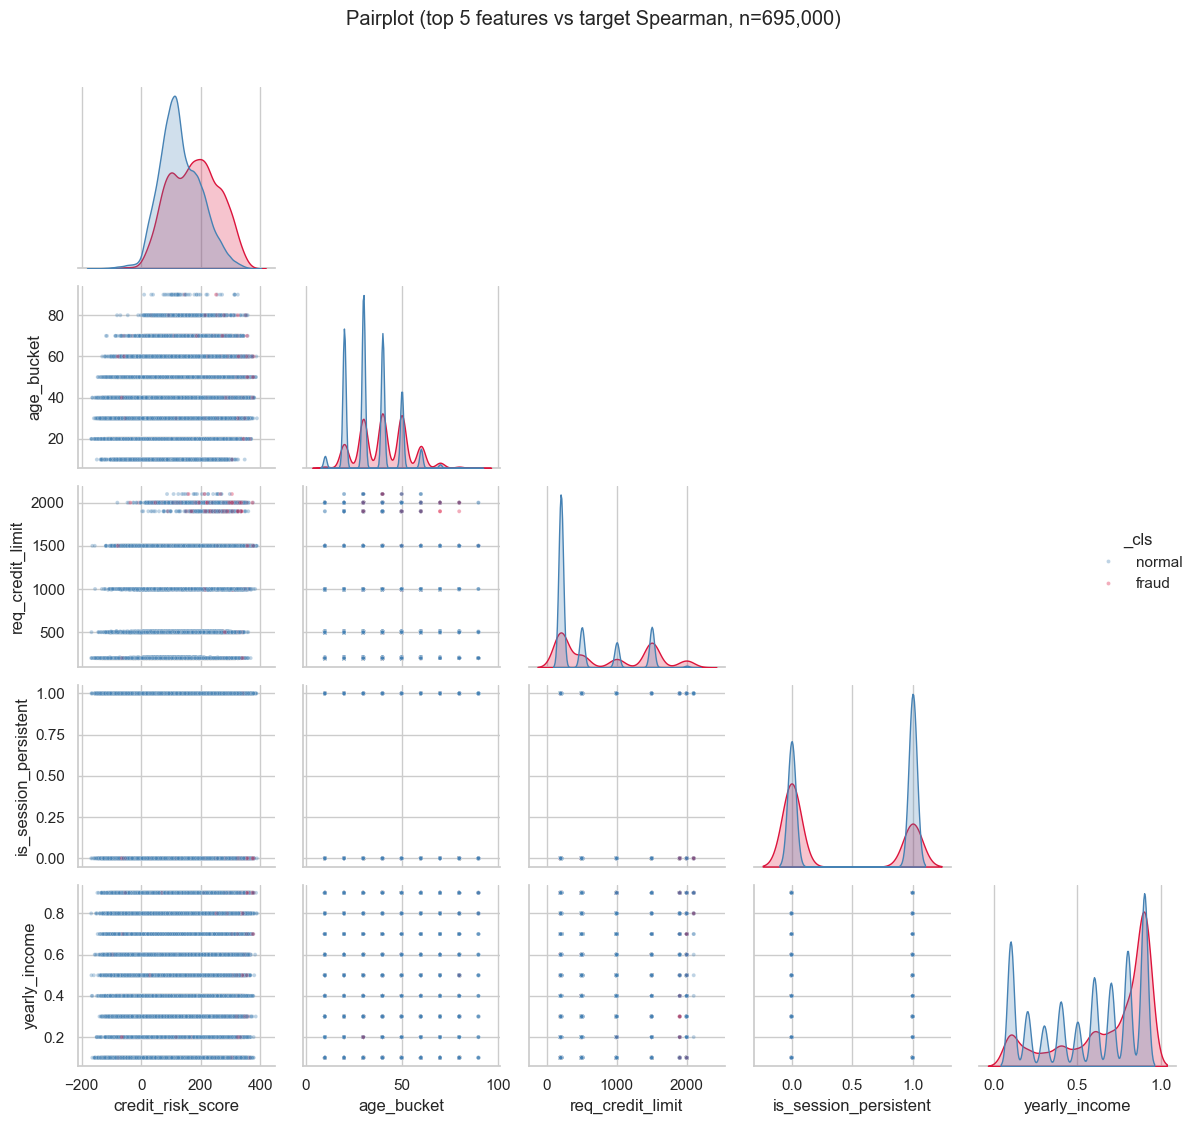

Pairplot: 354.6s | 저장: eda_corr_output\pairplot_top_features.png


In [ ]:
feats = tgt_df.head(PAIRPLOT_FEATS).index.tolist()
pp_df = X[feats].copy()
pp_df[TARGET] = y.values
pp_df["_cls"] = np.where(pp_df[TARGET].values > 0.5, "fraud", "normal")
if PAIRPLOT_SAMPLE is not None and len(pp_df) > PAIRPLOT_SAMPLE:
    _, pp_df = train_test_split(
        pp_df,
        train_size=PAIRPLOT_SAMPLE,
        stratify=pp_df[TARGET],
        random_state=SEED,
    )

t0 = time.perf_counter()
g = sns.pairplot(
    pp_df[feats + ["_cls"]],
    hue="_cls",
    corner=True,
    plot_kws={"s": 8, "alpha": 0.35},
    diag_kws={"common_norm": False},
    palette={"normal": "steelblue", "fraud": "crimson"},
    height=2.2,
)
g.fig.suptitle(
    f"Pairplot (top {PAIRPLOT_FEATS} features vs target Spearman, n={len(pp_df):,})",
    y=1.02,
)
plt.tight_layout()
fp = os.path.join(OUT_DIR, "pairplot_top_features.png")
g.savefig(fp, dpi=120, bbox_inches="tight")
plt.show()
print(f"Pairplot: {time.perf_counter() - t0:.1f}s | 저장: {fp}")

## 9) 강한 상관 네트워크 (선택)

**무엇을 하나요?**  
Spearman 행렬에서 \|ρ\| ≥ `CORR_NET_THR` 인 피처 쌍을 **엣지**로 두고, `networkx`로 **스프링 레이아웃** 그래프를 그립니다.

**왜 보나요?**  
같이 강하게 엮인 변수들이 **하나의 클러스터**로 묶여 보입니다. 임계값을 낮추면 선이 많아져 읽기 어려워집니다.

`networkx`가 없으면 이 셀은 건너뜁니다.

출력: `correlation_network_spearman.png`

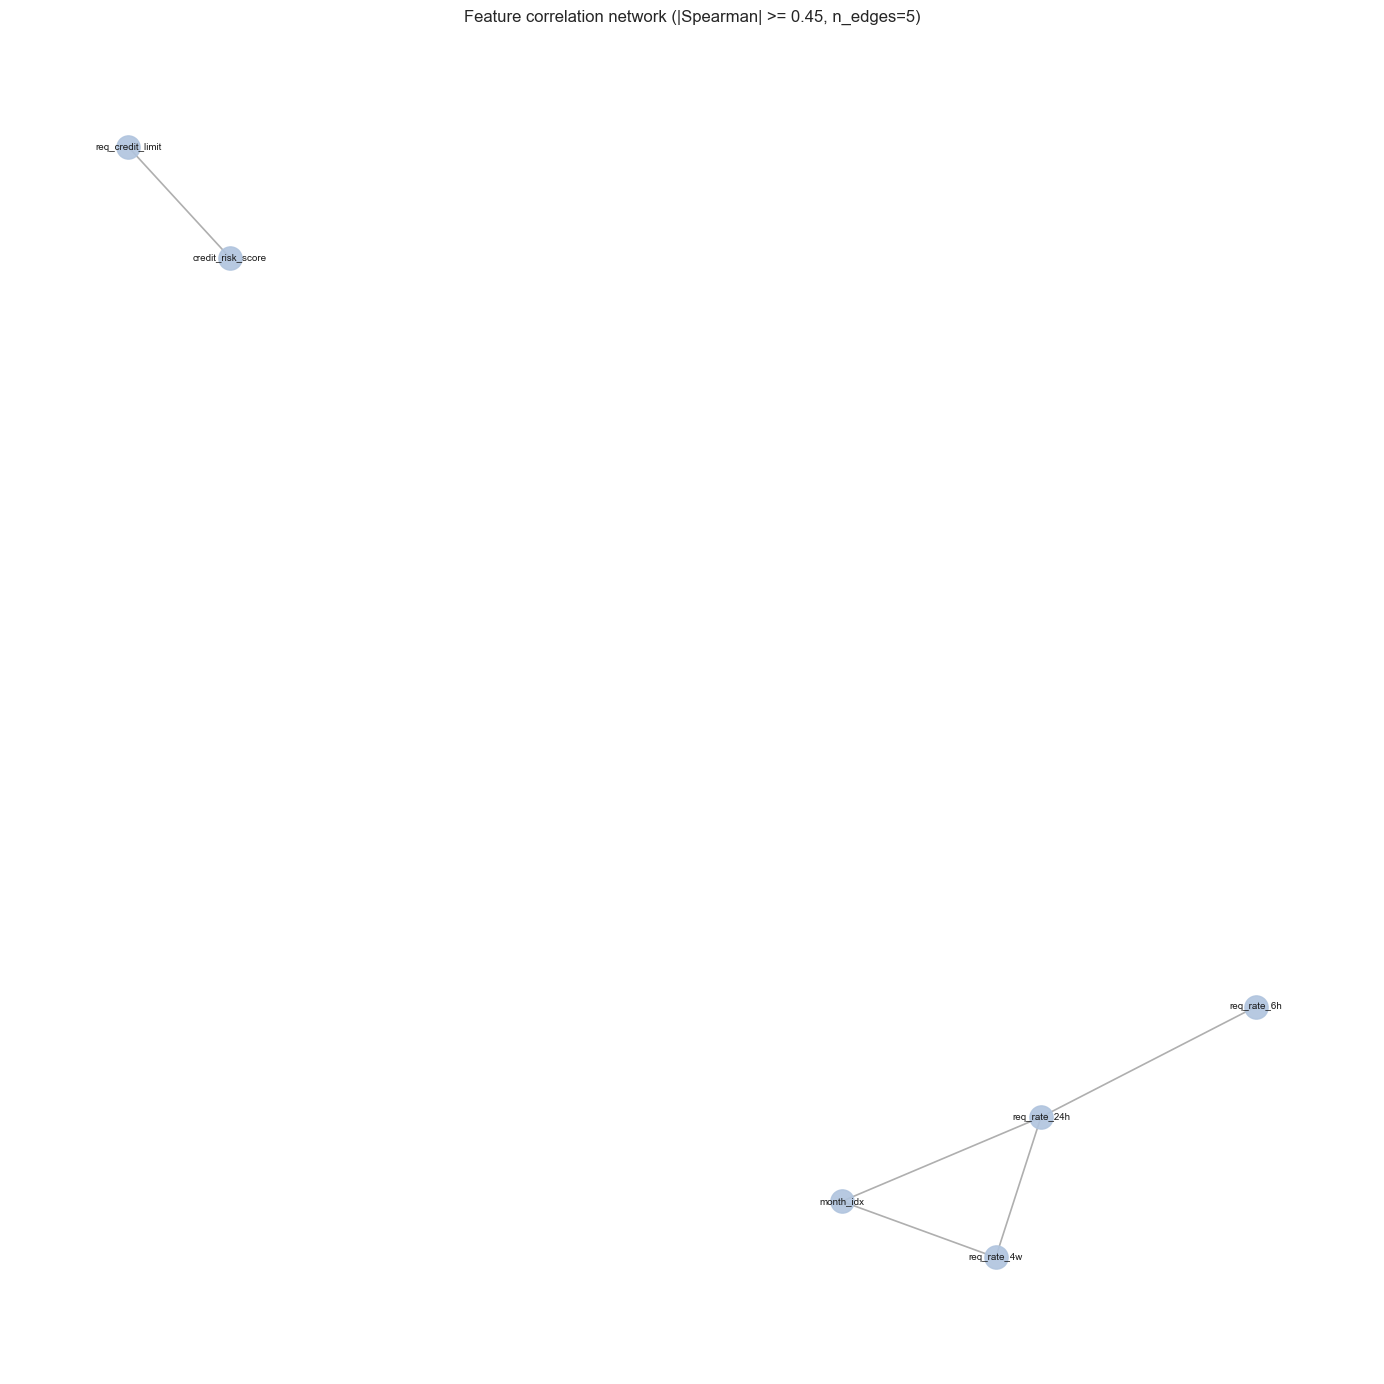

저장: eda_corr_output\correlation_network_spearman.png


In [ ]:
try:
    import networkx as nx
except ImportError:
    print("networkx 미설치 — pip install networkx 후 이 셀 재실행")
else:
    G = nx.Graph()
    cols = corr_s.columns.tolist()
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            a, b = cols[i], cols[j]
            rho = float(corr_s.loc[a, b])
            if abs(rho) >= CORR_NET_THR:
                G.add_edge(a, b, weight=abs(rho))
    plt.figure(figsize=(14, 14))
    pos = nx.spring_layout(G, seed=SEED, k=0.35, iterations=50)
    nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.2)
    nx.draw_networkx_nodes(G, pos, node_size=280, node_color="lightsteelblue", alpha=0.9)
    nx.draw_networkx_labels(G, pos, font_size=7)
    plt.title(
        f"Feature correlation network (|Spearman| >= {CORR_NET_THR}, n_edges={G.number_of_edges()})"
    )
    plt.axis("off")
    fp = os.path.join(OUT_DIR, "correlation_network_spearman.png")
    plt.tight_layout()
    plt.savefig(fp, dpi=150, bbox_inches="tight")
    plt.show()
    print("저장:", fp)

## 10) 나이(`age_bucket`) × 연간소득 · 거주형태 · 고용형태

**무엇을 하나요?**  
§2에서 읽은 **원시 `train`** 으로, 나이 구간과 (1) 연간소득이 **구간마다 어떻게 다른지**, (2) 거주·고용 범주와 **얼마나 연관되는지**를 **표 · 검정 · 그래프**로 봅니다.

**왜 보나요?**  
- 연간소득은 이 데이터에서 이산값(0.1~0.9 등)이라 **나이에 따라 분포가 달라질 수** 있습니다. 전체 Spearman 한 개보다 **구간별 요약**이 해석에 유리합니다.  
- 거주·고용은 범주형이라 **교차표 + 카이제곱 + Cramér’s V** 로 “연관 강도”를 숫자로 볼 수 있습니다.

**산출물** (`eda_corr_output/`): `age_income_*`, `age_housing_*`, `age_employment_*` 접두사 PNG·CSV.

> **주의:** 이 섹션은 숫자만 쓰는 §1~§9와 달리 **문자형 범주 컬럼**을 직접 사용합니다. `SAMPLE_N`으로 줄인 `train`이면 그 표본 기준입니다.

행 수: 700000

1) yearly_income vs age_bucket


,count,mean,median,std,min,max
age_bucket,,,,,,
10,14769,0.4227,0.4,0.2905,0.1,0.9
20,172253,0.5001,0.5,0.2917,0.1,0.9
30,217769,0.5673,0.6,0.2872,0.1,0.9
40,167171,0.6112,0.7,0.2801,0.1,0.9
50,98284,0.5993,0.7,0.2843,0.1,0.9
60,24236,0.5686,0.6,0.2895,0.1,0.9
70,4563,0.5608,0.6,0.2904,0.1,0.9
80,906,0.5600,0.6,0.2924,0.1,0.9
90,49,0.5673,0.6,0.2764,0.1,0.9


Spearman(age_bucket, yearly_income): rho = 0.14090, p = 0.000e+00
Kruskal-Wallis (yearly_income across age_bucket): H = 18288.259, p = 0.000e+00
One-way ANOVA (yearly_income ~ age_bucket): F = 2274.966, p = 0.000e+00
CSV: eda_corr_output\age_income_crosstab_count.csv
CSV: eda_corr_output\age_income_crosstab_row_fraction.csv


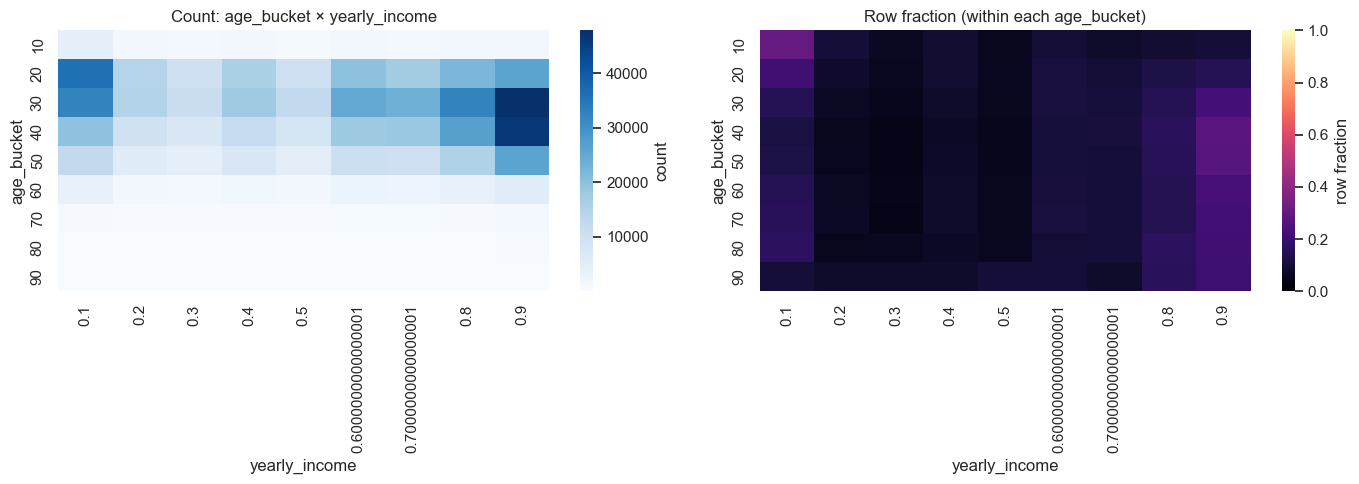

저장: eda_corr_output\age_income_heatmap_count_and_rowfrac.png


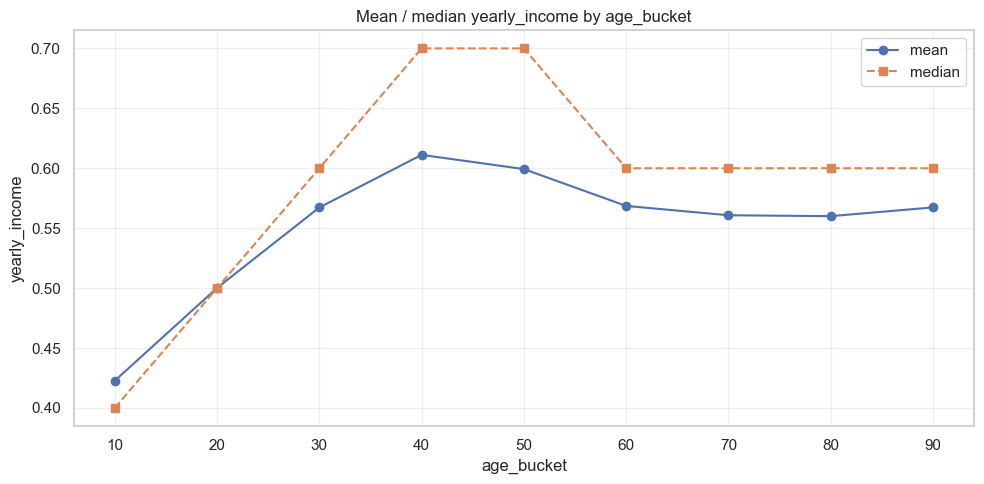

저장: eda_corr_output\age_income_mean_median_line.png


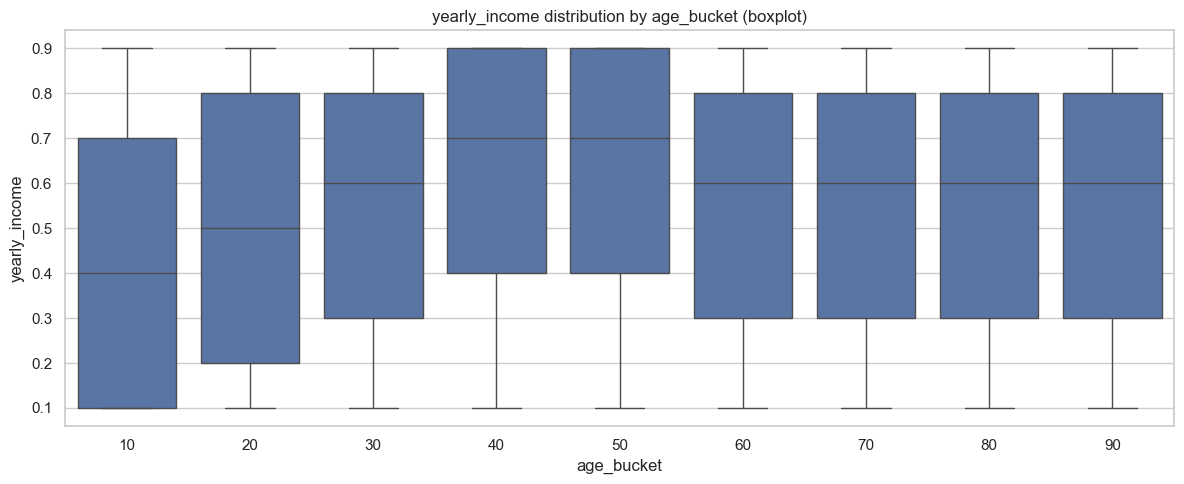

저장: eda_corr_output\age_income_boxplot.png


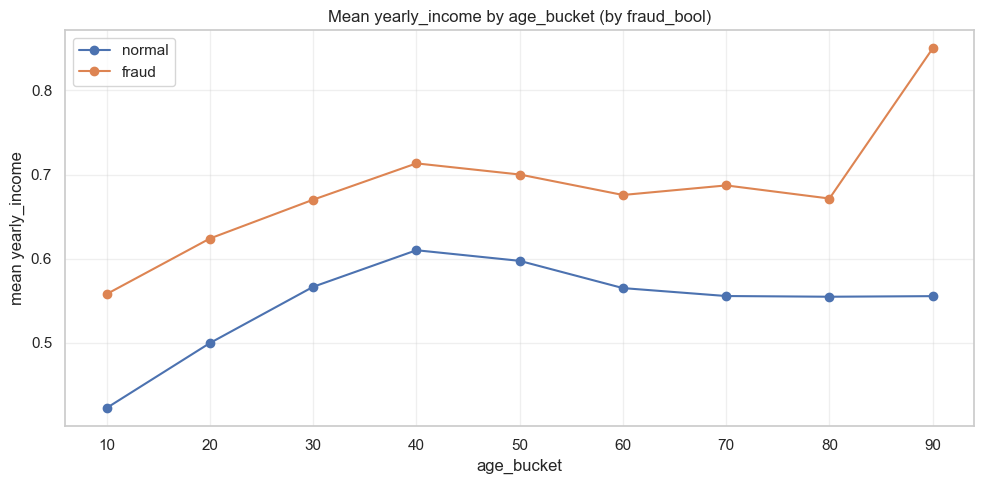

저장: eda_corr_output\age_income_mean_line_by_fraud.png

2) age_bucket vs housing_status
Chi-square: chi2=133473.451, p=0.000e+00
Cramér's V (age × housing): 0.1783  (대략: ~0.1 작음, ~0.3 중간, ~0.5 큼)


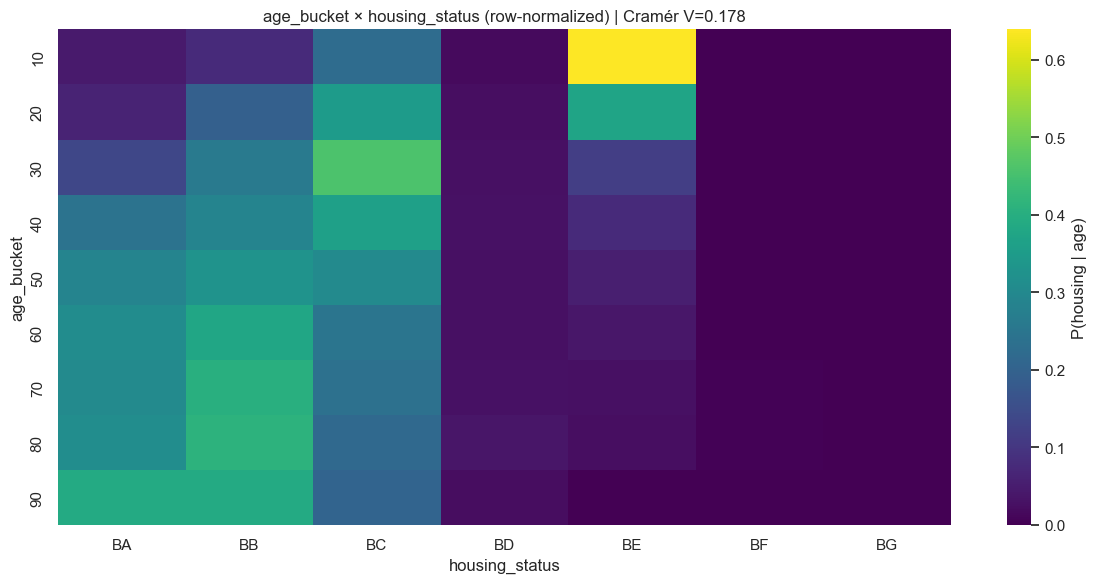

저장: eda_corr_output\age_housing_heatmap_rowfrac.png


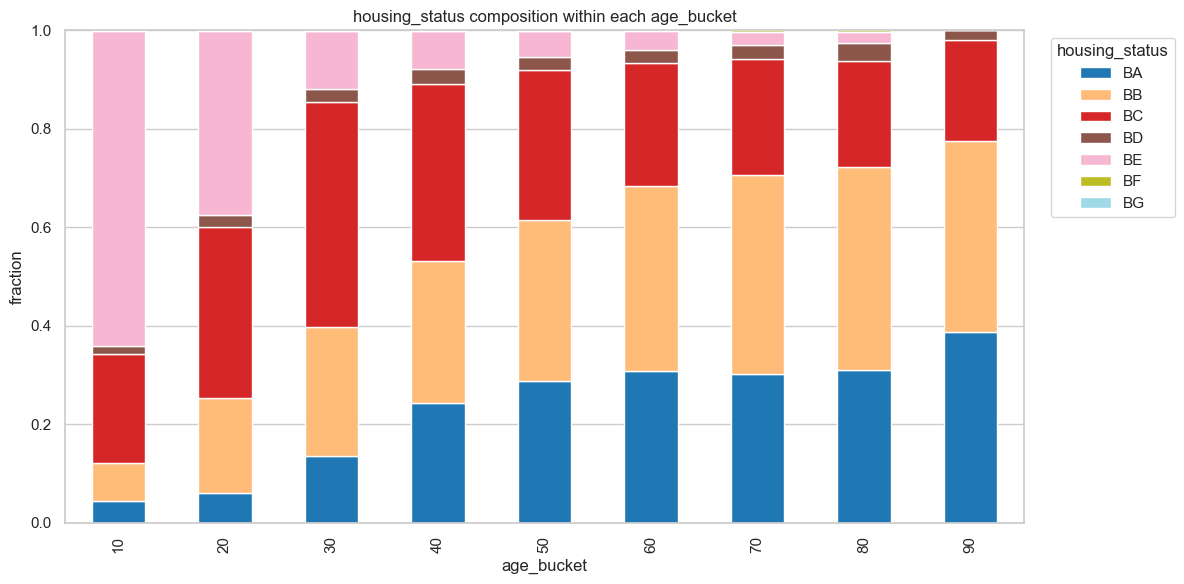

저장: eda_corr_output\age_housing_stacked_bar.png

3) age_bucket vs employment_status
Chi-square: chi2=121047.393, p=0.000e+00
Cramér's V (age × employment): 0.1698  (대략: ~0.1 작음, ~0.3 중간, ~0.5 큼)


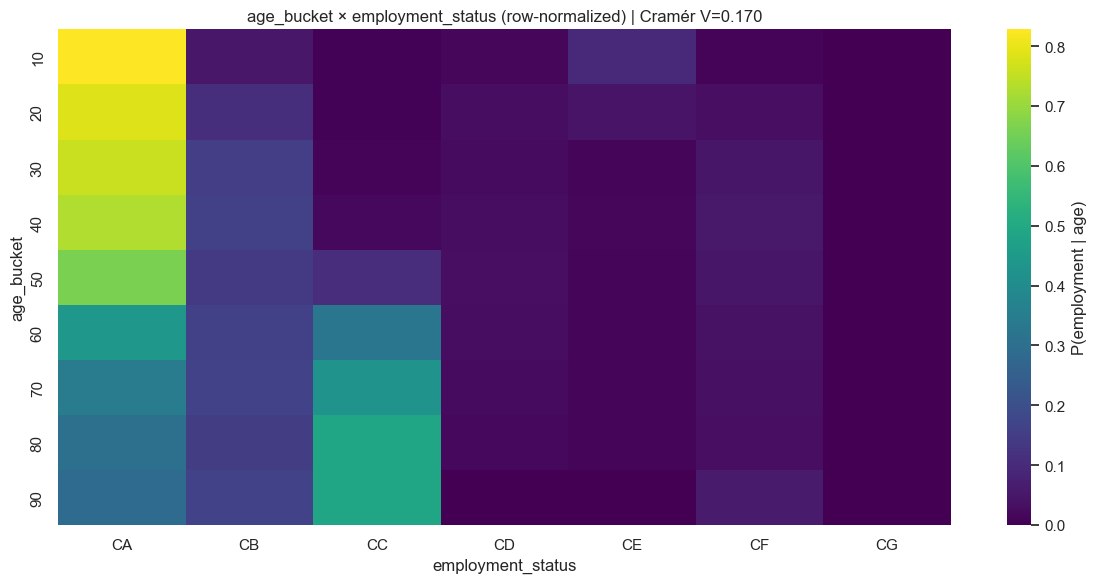

저장: eda_corr_output\age_employment_heatmap_rowfrac.png


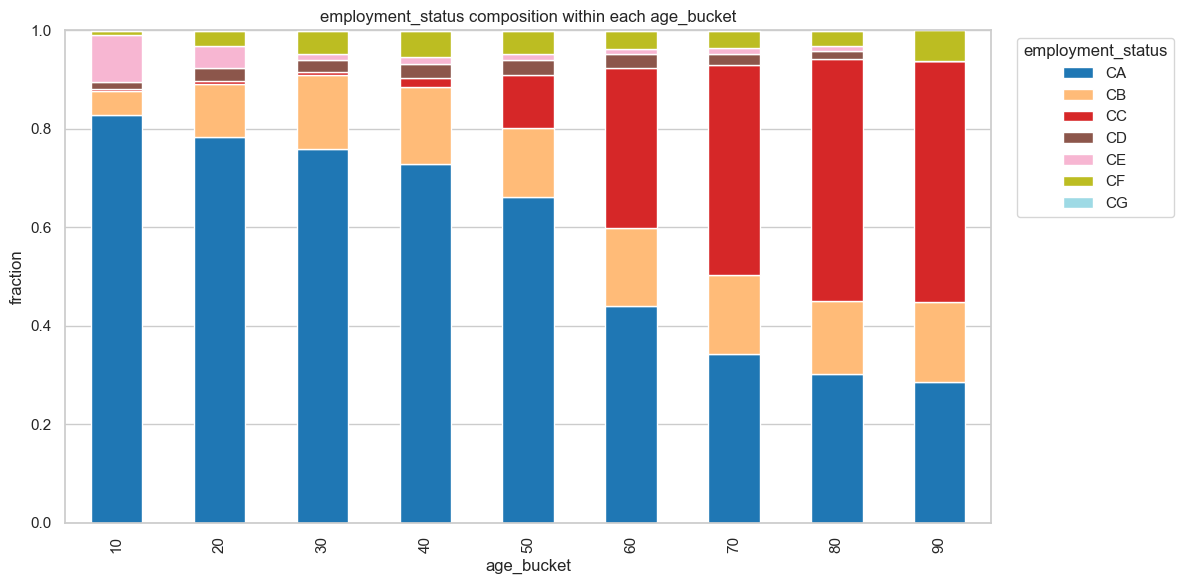

저장: eda_corr_output\age_employment_stacked_bar.png

§10 완료.


In [ ]:
# --- §10: age_bucket × yearly_income, housing_status, employment_status ---
from scipy.stats import spearmanr, kruskal, chi2_contingency, f_oneway

AGE, YI = "age_bucket", "yearly_income"
HS, ES = "housing_status", "employment_status"
TGT = TARGET  # fraud_bool from 설정 셀

t = train[[AGE, YI, HS, ES, TGT]].copy()
for c in (HS, ES):
    t[c] = t[c].astype(str).replace("nan", "(missing)")

# ---------- helpers ----------
def cramers_v(table: pd.DataFrame):
    """교차표 (관측 빈도). Cramér's V in [0,1]."""
    arr = np.asarray(table, dtype=float)
    if arr.size == 0 or arr.min() < 0:
        return np.nan, np.nan, np.nan
    chi2, p, dof, exp = chi2_contingency(arr)
    n = arr.sum()
    r, k = arr.shape
    if n <= 0 or r < 2 or k < 2:
        return np.nan, chi2, p
    denom = min(r - 1, k - 1)
    if denom <= 0:
        return np.nan, chi2, p
    v = np.sqrt((chi2 / n) / denom)
    return float(np.clip(v, 0.0, 1.0)), chi2, p


def savefig(name: str):
    fp = os.path.join(OUT_DIR, name)
    plt.tight_layout()
    plt.savefig(fp, dpi=150, bbox_inches="tight")
    plt.show()
    print("저장:", fp)


print("행 수:", len(t))
print()

# =============================================================================
# 1) 연간소득 × 나이
# =============================================================================
print("=" * 72)
print("1) yearly_income vs age_bucket")
print("=" * 72)

# 구간별 요약
g = t.groupby(AGE, observed=True)[YI].agg(["count", "mean", "median", "std", "min", "max"])
display(g.round(4))

# 전역 순위 상관 (나이 구간을 숫자로)
rho, p_sp = spearmanr(t[AGE], t[YI])
print(f"Spearman(age_bucket, yearly_income): rho = {rho:.5f}, p = {p_sp:.3e}")

# Kruskal-Wallis: 구간별 연간소득 분포가 같은가?
groups = [grp[YI].values for _, grp in t.groupby(AGE, observed=True) if len(grp) >= 1]
kw_stat, p_kw = kruskal(*groups)
print(f"Kruskal-Wallis (yearly_income across age_bucket): H = {kw_stat:.3f}, p = {p_kw:.3e}")

# 일원분산분석 (참고: 소득이 이산이라 정규성 가정은 엄밀하지 않음)
F_ow, p_ow = f_oneway(*groups)
print(f"One-way ANOVA (yearly_income ~ age_bucket): F = {F_ow:.3f}, p = {p_ow:.3e}")

# 교차: 나이 × 연간소득 값 (빈도 & 행 비율)
ct = pd.crosstab(t[AGE], t[YI], margins=False)
ct_row = ct.div(ct.sum(axis=1), axis=0)  # 각 나이 구간 안에서 소득 비율

fp_csv = os.path.join(OUT_DIR, "age_income_crosstab_count.csv")
ct.to_csv(fp_csv)
print("CSV:", fp_csv)
fp_csv2 = os.path.join(OUT_DIR, "age_income_crosstab_row_fraction.csv")
ct_row.to_csv(fp_csv2)
print("CSV:", fp_csv2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(ct, ax=axes[0], cmap="Blues", cbar_kws={"label": "count"})
axes[0].set_title("Count: age_bucket × yearly_income")
sns.heatmap(ct_row, ax=axes[1], cmap="magma", vmin=0, vmax=1, cbar_kws={"label": "row fraction"})
axes[1].set_title("Row fraction (within each age_bucket)")
for ax in axes:
    ax.set_xlabel("yearly_income")
    ax.set_ylabel("age_bucket")
savefig("age_income_heatmap_count_and_rowfrac.png")

# 평균/중앙값 라인
fig, ax = plt.subplots(figsize=(10, 5))
summary = t.groupby(AGE, observed=True)[YI].agg(["mean", "median"])
ax.plot(summary.index.astype("float64"), summary["mean"], "o-", label="mean")
ax.plot(summary.index.astype("float64"), summary["median"], "s--", label="median")
ax.set_xlabel("age_bucket")
ax.set_ylabel("yearly_income")
ax.set_title("Mean / median yearly_income by age_bucket")
ax.legend()
ax.grid(True, alpha=0.3)
savefig("age_income_mean_median_line.png")

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=t, x=AGE, y=YI, ax=ax, order=sorted(t[AGE].unique()))
ax.set_title("yearly_income distribution by age_bucket (boxplot)")
savefig("age_income_boxplot.png")

# 사기 여부로 나눈 평균 (참고)
if TGT in t.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    for fv, lab in [(0, "normal"), (1, "fraud")]:
        sub = t[t[TGT] == fv]
        m = sub.groupby(AGE, observed=True)[YI].mean()
        ax.plot(m.index.astype(float), m.values, "o-", label=lab)
    ax.set_xlabel("age_bucket")
    ax.set_ylabel("mean yearly_income")
    ax.set_title("Mean yearly_income by age_bucket (by fraud_bool)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    savefig("age_income_mean_line_by_fraud.png")

print()

# =============================================================================
# 2) 나이 × 거주형태
# =============================================================================
print("=" * 72)
print("2) age_bucket vs housing_status")
print("=" * 72)

ct_h = pd.crosstab(t[AGE], t[HS])
v_h, chi2_h, p_h = cramers_v(ct_h)
print(f"Chi-square: chi2={chi2_h:.3f}, p={p_h:.3e}")
print(f"Cramér's V (age × housing): {v_h:.4f}  (대략: ~0.1 작음, ~0.3 중간, ~0.5 큼)")

ct_h.to_csv(os.path.join(OUT_DIR, "age_housing_crosstab_count.csv"))
ct_h_norm = ct_h.div(ct_h.sum(axis=1), axis=0)
ct_h_norm.to_csv(os.path.join(OUT_DIR, "age_housing_row_fraction.csv"))

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(ct_h_norm, cmap="viridis", ax=ax, cbar_kws={"label": "P(housing | age)"})
ax.set_title(f"age_bucket × housing_status (row-normalized) | Cramér V={v_h:.3f}")
savefig("age_housing_heatmap_rowfrac.png")

# stacked bar: 각 나이에서 housing 비율
ct_h_frac = ct_h.div(ct_h.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 6))
ct_h_frac.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", legend=False)
ax.set_ylabel("fraction")
ax.set_xlabel("age_bucket")
ax.set_title("housing_status composition within each age_bucket")
ax.legend(ct_h_frac.columns, title=HS, bbox_to_anchor=(1.02, 1), loc="upper left")
savefig("age_housing_stacked_bar.png")

print()

# =============================================================================
# 3) 나이 × 고용형태
# =============================================================================
print("=" * 72)
print("3) age_bucket vs employment_status")
print("=" * 72)

ct_e = pd.crosstab(t[AGE], t[ES])
v_e, chi2_e, p_e = cramers_v(ct_e)
print(f"Chi-square: chi2={chi2_e:.3f}, p={p_e:.3e}")
print(f"Cramér's V (age × employment): {v_e:.4f}  (대략: ~0.1 작음, ~0.3 중간, ~0.5 큼)")

ct_e.to_csv(os.path.join(OUT_DIR, "age_employment_crosstab_count.csv"))
ct_e_norm = ct_e.div(ct_e.sum(axis=1), axis=0)
ct_e_norm.to_csv(os.path.join(OUT_DIR, "age_employment_row_fraction.csv"))

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(ct_e_norm, cmap="viridis", ax=ax, cbar_kws={"label": "P(employment | age)"})
ax.set_title(f"age_bucket × employment_status (row-normalized) | Cramér V={v_e:.3f}")
savefig("age_employment_heatmap_rowfrac.png")

ct_e_frac = ct_e.div(ct_e.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 6))
ct_e_frac.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", legend=False)
ax.set_ylabel("fraction")
ax.set_xlabel("age_bucket")
ax.set_title("employment_status composition within each age_bucket")
ax.legend(ct_e_frac.columns, title=ES, bbox_to_anchor=(1.02, 1), loc="upper left")
savefig("age_employment_stacked_bar.png")

print()
print("§10 완료.")

## 11) 나이(`age_bucket`) × 전체 나머지 피처 (§10 수준 속도)

- **`AGE11_MAX_ROWS`**: 상관·요약·그림에 쓰는 행 수(기본 12만). `None`이면 `train` 전체(느려짐·RAM↑).
- **범주형**: `age_bucket`별 해당 피처 범주 **구성비(행 정규화)** 누적 막대 PNG를 **피처마다** 저장.
- **숫자형/불리언**: `pd.qcut`으로 구간(기본 최대 10분위)을 만든 뒤 **같은 형식**의 누적 막대.
- **`AGE11_MAX_CAT_LEVELS`**: 범주 수가 많으면 상위 N-1 + `(other)` 로 묶어 범례·속도를 맞춤.
- **`AGE11_STACK_DIR`**: PNG 저장 폴더 (`eda_corr_output/age11_stacked_by_feature/`).
- **`RUN_PAIRWISE_FEATURE_STACKS`**: `True`이면 **모든 피처 쌍 (P,G), P≠G** 에 대해 `age×G`와 동일하게 **P 축·막대 안에서 G의 행 정규화 fraction** 누적 막대(피처 N개면 최대 약 N×(N−1)장).
- **`PAIRWISE_STACK_DIR`**, **`PAIRWISE_NUM_BINS`**, **`PAIRWISE_MAX_CAT_LEVELS`**: pairwise 출력 폴더·숫자 구간 분할·범주 상한.



§11: 속도용 표본 120,000행 (AGE11_MAX_ROWS=120000)
CSV: eda_corr_output\age11_summary_all_features.csv


,feature,kind,n_valid,spearman_rho,spearman_p,cramers_v,chi2_p
29,application_source,categorical,120000,NaN,NaN,0.026311,1.175374e-14
17,bank_months_count,numeric,120000,0.011935,3.555652e-05,NaN,NaN
11,branch_req_count_8w,numeric,120000,0.039814,2.645805e-43,NaN,NaN
13,credit_risk_score,numeric,120000,0.162906,0.000000e+00,NaN,NaN
4,curr_addr_months,numeric,120000,0.165834,0.000000e+00,NaN,NaN
5,days_since_req,numeric,120000,0.008709,2.554398e-03,NaN,NaN
23,device_email_cnt_8w,numeric,120000,0.031428,1.292976e-27,NaN,NaN
24,device_fraud_history,numeric,120000,NaN,NaN,NaN,NaN
30,device_os,categorical,120000,NaN,NaN,0.081612,0.000000e+00
12,dob_email_count_4w,numeric,120000,-0.443791,0.000000e+00,NaN,NaN


CSV: eda_corr_output\age11_numeric_spearman_ranked.csv
CSV: eda_corr_output\age11_categorical_cramers_ranked.csv


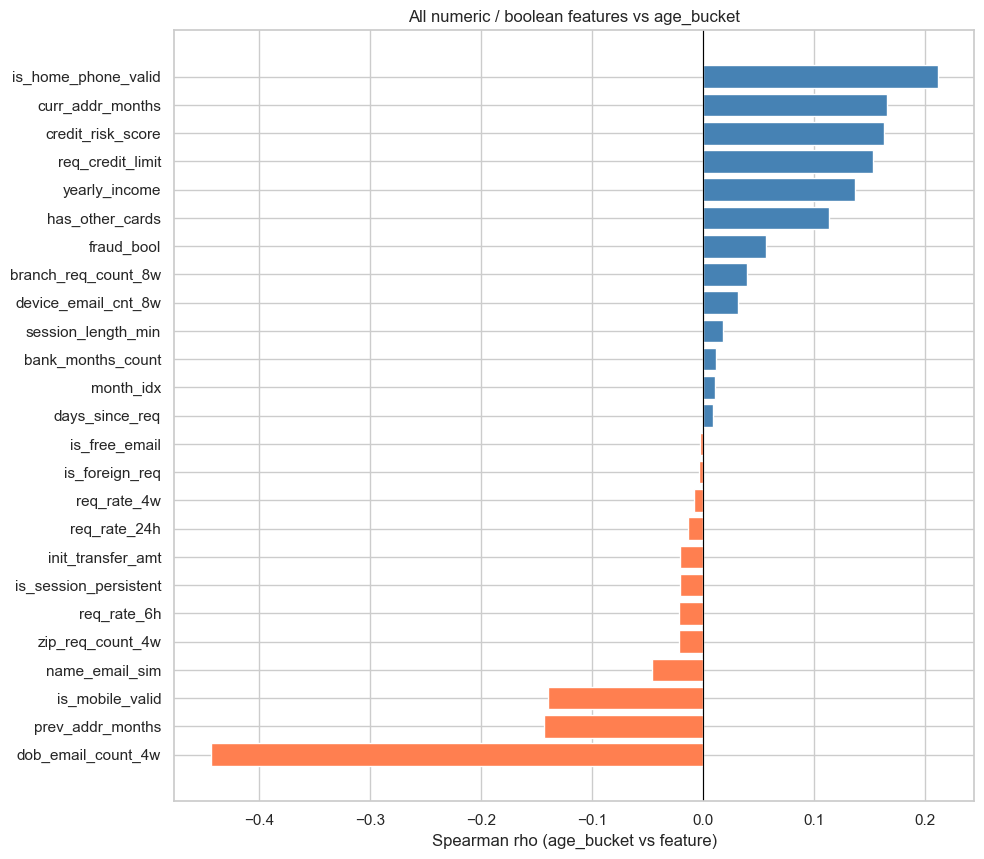

저장: eda_corr_output\age11_bar_spearman_all_numeric.png


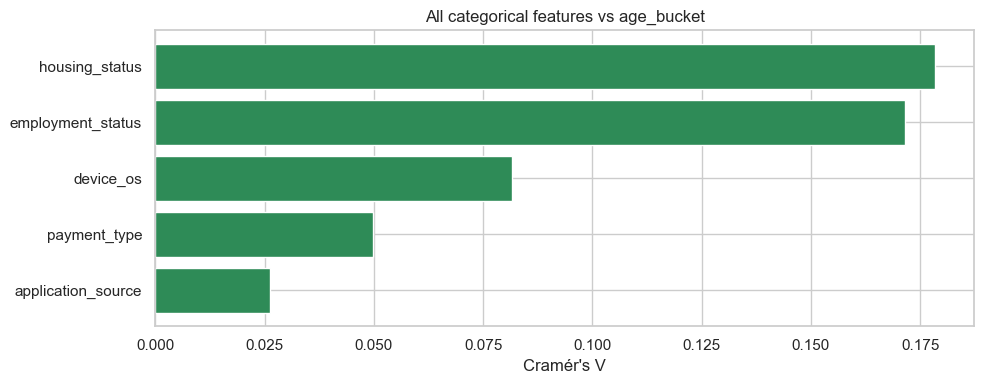

저장: eda_corr_output\age11_bar_cramers_all_categorical.png


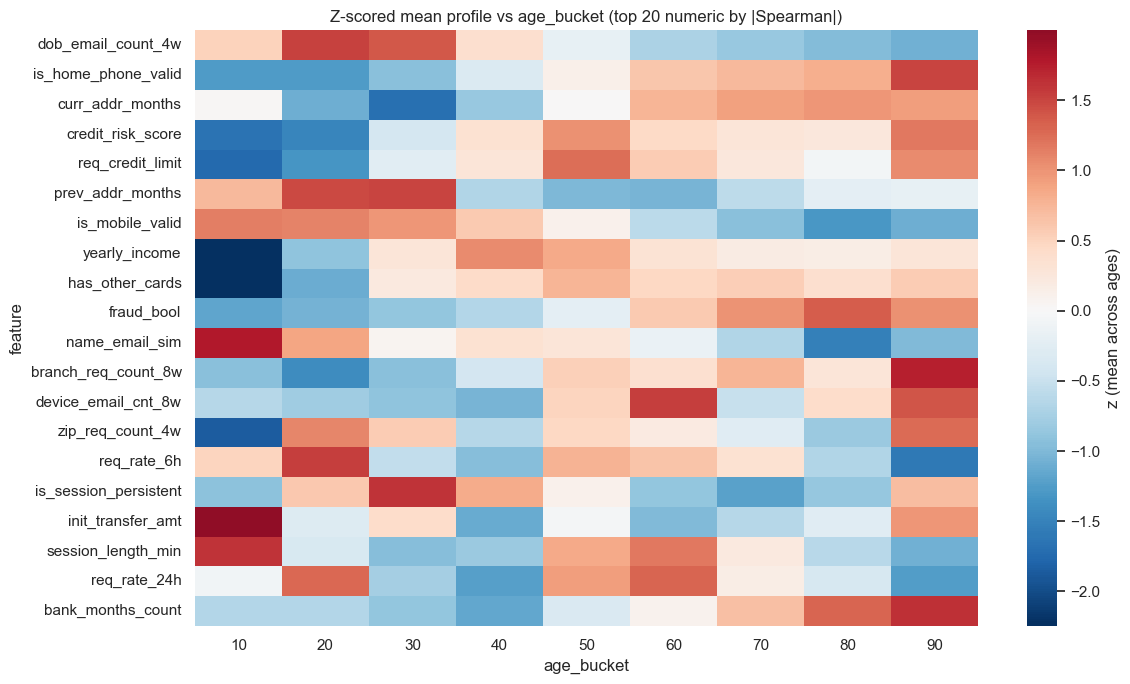

저장: eda_corr_output\age11_heatmap_mean_zscore_top_numeric.png
§10 스타일 누적 막대 저장: eda_corr_output\age11_stacked_by_feature
  pairwise 누적 막대: 50 / ~992 …
  pairwise 누적 막대: 100 / ~992 …
  pairwise 누적 막대: 150 / ~992 …
  pairwise 누적 막대: 200 / ~992 …
  pairwise 누적 막대: 250 / ~992 …
  pairwise 누적 막대: 300 / ~992 …
  pairwise 누적 막대: 350 / ~992 …
  pairwise 누적 막대: 400 / ~992 …
  pairwise 누적 막대: 450 / ~992 …
  pairwise 누적 막대: 500 / ~992 …
  pairwise 누적 막대: 550 / ~992 …
  pairwise 누적 막대: 600 / ~992 …
  pairwise 누적 막대: 650 / ~992 …
  pairwise 누적 막대: 700 / ~992 …
  pairwise 누적 막대: 750 / ~992 …
  pairwise 누적 막대: 800 / ~992 …
  pairwise 누적 막대: 850 / ~992 …
  pairwise 누적 막대: 900 / ~992 …
pairwise_feature_stacks 저장: eda_corr_output\pairwise_feature_stacks (930 PNG)
누적 막대 PNG: 5 범주 + 26 숫자 (실제 저장은 유효 행만)

§11 완료.


In [ ]:
# --- §11: age_bucket vs 전체 피처 (§10과 같은 누적 막대, 피처별 전부) ---
from scipy.stats import spearmanr, chi2_contingency

AGE = "age_bucket"
EXCLUDE = {"id", AGE}

AGE11_MAX_ROWS = 120_000
AGE11_TOP_NUM_FOR_HEATMAP = 20
AGE11_NUM_BINS = 10
AGE11_MAX_CAT_LEVELS = 25

RUN_PAIRWISE_FEATURE_STACKS = True
PAIRWISE_STACK_DIR = os.path.join(OUT_DIR, "pairwise_feature_stacks")
PAIRWISE_NUM_BINS = 10
PAIRWISE_MAX_CAT_LEVELS = 25

AGE11_STACK_DIR = os.path.join(OUT_DIR, "age11_stacked_by_feature")


def _cramers_v_arr(arr):
    arr = np.asarray(arr, dtype=float)
    if arr.size == 0 or arr.min() < 0:
        return np.nan, np.nan, np.nan
    chi2, p, dof, exp = chi2_contingency(arr)
    n = arr.sum()
    r, k = arr.shape
    if n <= 0 or r < 2 or k < 2:
        return np.nan, chi2, p
    denom = min(r - 1, k - 1)
    if denom <= 0:
        return np.nan, chi2, p
    v = np.sqrt((chi2 / n) / denom)
    return float(np.clip(v, 0.0, 1.0)), chi2, p


def _savefig(name: str):
    fp = os.path.join(OUT_DIR, name)
    plt.tight_layout()
    plt.savefig(fp, dpi=150, bbox_inches="tight")
    plt.show()
    print("저장:", fp)


def _safe_feature_fname(name: str) -> str:
    s = "".join(ch if (ch.isalnum() or ch in "._-") else "_" for ch in str(name))
    return s[:150] if len(s) > 150 else s


def _savefig_quiet(path: str) -> None:
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close()


def _stacked_bar_rowfrac(ct_row: pd.DataFrame, *, title: str, fp: str, legend_title: str, xlabel: str = "age_bucket") -> None:
    fig, ax = plt.subplots(figsize=(12, 6))
    ct_row.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", legend=False, width=0.9)
    ax.set_ylabel("fraction")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(ct_row.columns, title=legend_title, bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.set_ylim(0, 1)
    _savefig_quiet(fp)


def _levels_for_pairwise(df: pd.DataFrame, col: str, *, num_bins: int, max_cat: int) -> pd.Series:
    """각 행을 문자열 구간/범주로 (pairwise 누적 막대용)."""
    s = df[col]
    if pd.api.types.is_bool_dtype(s):
        s = s.astype(np.float64)
    if pd.api.types.is_numeric_dtype(s) or pd.api.types.is_bool_dtype(s):
        out = pd.Series(np.nan, index=df.index, dtype=object)
        m = s.notna()
        if not m.any():
            return out
        sv = s[m]
        nuniq = int(sv.nunique())
        if nuniq <= 1:
            return out
        if nuniq <= 10:
            out.loc[m] = sv.astype(str).values
        else:
            q = min(num_bins, nuniq)
            try:
                b = pd.qcut(sv, q=q, duplicates="drop")
            except ValueError:
                b = pd.cut(sv, bins=min(num_bins, nuniq))
            out.loc[m] = b.astype(str).values
        return out
    out = s.astype(str).replace("nan", "(missing)")
    vc = out.value_counts()
    if len(vc) > max_cat:
        top = set(vc.nlargest(max_cat - 1).index)
        out = out.where(out.isin(top), "(other)")
    return out


df = train.copy()
if AGE not in df.columns:
    raise ValueError("train에 age_bucket이 필요합니다. 데이터 로드 셀을 먼저 실행하세요.")

if AGE11_MAX_ROWS is not None and len(df) > AGE11_MAX_ROWS:
    df = df.sample(n=AGE11_MAX_ROWS, random_state=SEED)
    print(f"§11: 속도용 표본 {len(df):,}행 (AGE11_MAX_ROWS={AGE11_MAX_ROWS})")

feat_cols = [c for c in df.columns if c not in EXCLUDE]
num_cols = [
    c
    for c in feat_cols
    if pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c])
]
cat_cols = [c for c in feat_cols if c not in num_cols]

rows = []
for col in num_cols:
    pair = df[[AGE, col]].copy()
    if pair[col].dtype == bool:
        pair[col] = pair[col].astype(np.float64)
    pair = pair.dropna()
    n = len(pair)
    if n < 30:
        rho, p_sp = np.nan, np.nan
    else:
        rho, p_sp = spearmanr(pair[AGE].astype(float), pair[col])
    rows.append(
        {
            "feature": col,
            "kind": "numeric",
            "n_valid": n,
            "spearman_rho": rho,
            "spearman_p": p_sp,
            "cramers_v": np.nan,
            "chi2_p": np.nan,
        }
    )

for col in cat_cols:
    sub = df[[AGE, col]].dropna()
    sub = sub.assign(_c=sub[col].astype(str))
    sub["_c"] = sub["_c"].replace("nan", "(missing)")
    n = len(sub)
    if n < 30:
        v, p_chi = np.nan, np.nan
    else:
        ct = pd.crosstab(sub[AGE], sub["_c"])
        v, chi2, p_chi = _cramers_v_arr(ct.values)
    rows.append(
        {
            "feature": col,
            "kind": "categorical",
            "n_valid": n,
            "spearman_rho": np.nan,
            "spearman_p": np.nan,
            "cramers_v": v,
            "chi2_p": p_chi,
        }
    )

summary = pd.DataFrame(rows)
fp_all = os.path.join(OUT_DIR, "age11_summary_all_features.csv")
summary.to_csv(fp_all, index=False)
print("CSV:", fp_all)
display(summary.sort_values("feature"))

num_df = summary[summary["kind"] == "numeric"].copy()
num_df["abs_rho"] = num_df["spearman_rho"].abs()
num_df = num_df.sort_values("abs_rho", ascending=False)
fp_num = os.path.join(OUT_DIR, "age11_numeric_spearman_ranked.csv")
num_df.to_csv(fp_num, index=False)
print("CSV:", fp_num)

cat_df = summary[summary["kind"] == "categorical"].copy()
cat_df = cat_df.sort_values("cramers_v", ascending=False)
fp_cat = os.path.join(OUT_DIR, "age11_categorical_cramers_ranked.csv")
cat_df.to_csv(fp_cat, index=False)
print("CSV:", fp_cat)

plot_n = num_df.dropna(subset=["spearman_rho"]).sort_values("spearman_rho")
if len(plot_n) == 0:
    print("경고: 숫자 피처 Spearman이 모두 NaN — 막대 생략")
else:
    fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(plot_n))))
    colors = np.where(plot_n["spearman_rho"].values >= 0, "steelblue", "coral")
    ax.barh(plot_n["feature"], plot_n["spearman_rho"], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Spearman rho (age_bucket vs feature)")
    ax.set_title("All numeric / boolean features vs age_bucket")
    _savefig("age11_bar_spearman_all_numeric.png")

if len(cat_cols) > 0:
    plot_c = cat_df.dropna(subset=["cramers_v"]).sort_values("cramers_v")
    if len(plot_c) == 0:
        print("경고: 범주형 Cramér's V가 모두 NaN — 막대 생략")
    else:
        fig, ax = plt.subplots(figsize=(10, max(4, 0.4 * len(plot_c))))
        ax.barh(plot_c["feature"], plot_c["cramers_v"], color="seagreen")
        ax.set_xlabel("Cramér's V")
        ax.set_title("All categorical features vs age_bucket")
        _savefig("age11_bar_cramers_all_categorical.png")

num_ok = num_df.dropna(subset=["spearman_rho"]).copy()
topn = min(AGE11_TOP_NUM_FOR_HEATMAP, len(num_ok))
if topn > 0:
    top_feats = num_ok.head(topn)["feature"].tolist()
    mean_by_age = train.groupby(AGE, observed=True)[top_feats].mean()
    zprof = (mean_by_age - mean_by_age.mean(axis=0)) / mean_by_age.std(axis=0).replace(0, np.nan)
    fig, ax = plt.subplots(figsize=(12, max(5, 0.35 * topn)))
    sns.heatmap(zprof.T, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "z (mean across ages)"})
    ax.set_title(f"Z-scored mean profile vs age_bucket (top {topn} numeric by |Spearman|)")
    ax.set_xlabel("age_bucket")
    ax.set_ylabel("feature")
    _savefig("age11_heatmap_mean_zscore_top_numeric.png")

os.makedirs(AGE11_STACK_DIR, exist_ok=True)
print("§10 스타일 누적 막대 저장:", AGE11_STACK_DIR)

for j, col in enumerate(cat_cols, 1):
    sub = df[[AGE, col]].dropna()
    if len(sub) < 10:
        continue
    sub = sub.assign(_c=sub[col].astype(str).replace("nan", "(missing)"))
    vc = sub["_c"].value_counts()
    if len(vc) > AGE11_MAX_CAT_LEVELS:
        top = set(vc.nlargest(AGE11_MAX_CAT_LEVELS - 1).index)
        sub["_c"] = sub["_c"].where(sub["_c"].isin(top), "(other)")
    ct = pd.crosstab(sub[AGE], sub["_c"])
    if ct.size == 0 or ct.sum().sum() == 0:
        continue
    ct_row = ct.div(ct.sum(axis=1), axis=0)
    fp = os.path.join(AGE11_STACK_DIR, f"stack_cat__{_safe_feature_fname(col)}.png")
    _stacked_bar_rowfrac(
        ct_row,
        title=f"{col} composition within each age_bucket",
        fp=fp,
        legend_title=col,
    )

for i, col in enumerate(num_cols, 1):
    sub = df[[AGE, col]].copy()
    if sub[col].dtype == bool:
        sub[col] = sub[col].astype(np.float64)
    sub = sub.dropna()
    if len(sub) < 30:
        continue
    nuniq = int(sub[col].nunique())
    if nuniq <= 1:
        continue
    if nuniq <= 10:
        sub = sub.assign(_b=sub[col].astype(str))
    else:
        q = min(AGE11_NUM_BINS, nuniq)
        try:
            sub = sub.assign(_b=pd.qcut(sub[col], q=q, duplicates="drop"))
        except ValueError:
            sub = sub.assign(_b=pd.cut(sub[col], bins=min(AGE11_NUM_BINS, nuniq)))
        sub["_b"] = sub["_b"].astype(str)
    ct = pd.crosstab(sub[AGE], sub["_b"])
    if ct.size == 0 or ct.sum().sum() == 0:
        continue
    ct_row = ct.div(ct.sum(axis=1), axis=0)
    fp = os.path.join(AGE11_STACK_DIR, f"stack_num__{_safe_feature_fname(col)}.png")
    _stacked_bar_rowfrac(
        ct_row,
        title=f"{col} (binned) composition within each age_bucket",
        fp=fp,
        legend_title=col,
    )

if RUN_PAIRWISE_FEATURE_STACKS:
    os.makedirs(PAIRWISE_STACK_DIR, exist_ok=True)
    all_cols = [c for c in df.columns if c != "id"]
    cache = {
        c: _levels_for_pairwise(df, c, num_bins=PAIRWISE_NUM_BINS, max_cat=PAIRWISE_MAX_CAT_LEVELS)
        for c in all_cols
    }
    total_pairs = len(all_cols) * (len(all_cols) - 1)
    n_pair = 0
    for p in all_cols:
        sp = cache[p]
        for g in all_cols:
            if p == g:
                continue
            sg = cache[g]
            sub = pd.DataFrame({"p": sp, "g": sg}).dropna()
            if len(sub) < 10:
                continue
            ct = pd.crosstab(sub["p"], sub["g"])
            if ct.size == 0 or ct.sum().sum() == 0:
                continue
            ct_row = ct.div(ct.sum(axis=1), axis=0)
            fp = os.path.join(
                PAIRWISE_STACK_DIR,
                f"stack__{_safe_feature_fname(p)}__{_safe_feature_fname(g)}.png",
            )
            _stacked_bar_rowfrac(
                ct_row,
                title=f"{g} composition within each {p}",
                fp=fp,
                legend_title=g,
                xlabel=str(p),
            )
            n_pair += 1
            if n_pair % 50 == 0:
                print(f"  pairwise 누적 막대: {n_pair} / ~{total_pairs} …")
    print("pairwise_feature_stacks 저장:", PAIRWISE_STACK_DIR, f"({n_pair} PNG)")

print(f"누적 막대 PNG: {len(cat_cols)} 범주 + {len(num_cols)} 숫자 (실제 저장은 유효 행만)")
print()
print("§11 완료.")


---

**산출물** (`eda_corr_output/`)

| 파일 | 내용 |
|------|------|
| `corr_spearman_features.csv` / `corr_pearson_features.csv` | 피처 간 전체 행렬 |
| `clustermap_spearman.png` / `clustermap_pearson.png` | 계층적 클러스터 히트맵 |
| `corr_with_target_fraud_bool.csv` | 타깃과의 Pearson/Spearman |
| `bar_target_top30.png` | 타깃 상관 상위 막대 |
| `scatter_pearson_vs_spearman_target.png` | 피처별 선형 vs 순위 상관 비교 |
| `strong_pairwise_spearman.csv` | 강한 피처 쌍 목록 |
| `heatmap_top*_spearman_submatrix.png` | 상위 K 피처 부분 행렬 |
| `mutual_info_target.csv` / `bar_mutual_info_top30.png` | Mutual Information (타깃) |
| `bootstrap_spearman_target_ci.csv` / `bootstrap_spearman_ci_errorbar.png` | 부트스트랩 CI |
| `pairplot_top_features.png` | 상위 피처 Pairplot |
| `correlation_network_spearman.png` | 강한 상관 네트워크 (networkx) |
| `age_income_*.png`, `age_income_crosstab_*.csv` | 나이×연간소득 (히트맵·평균선·박스플롯·사기별 참고) |
| `age_housing_*.png`, `age_housing_crosstab_*.csv` | 나이×거주 (교차표·행비율 히트맵·누적 막대) |
| `age_employment_*.png`, `age_employment_crosstab_*.csv` | 나이×고용 (동일) |
| `age11_*.csv`, `age11_bar_*.png`, `age11_heatmap_mean_zscore_top_numeric.png` | 나이×전체 피처 요약(§11) |
| `age11_stacked_by_feature/stack_*.png` | 나이×각 피처 **§10형 누적 막대**(범주 전부 + 숫자는 분위 구간) |
| `pairwise_feature_stacks/stack__*__*.png` | 기준 피처 P마다 다른 피처 G의 분포(행 정규화 누적 막대), age×단일피처와 동일 로직 |

느린 옵션: `MI_MAX_ROWS`, `BOOTSTRAP_B`, `BOOTSTRAP_SUB`, `PAIRPLOT_SAMPLE`, `CORR_NET_THR` 를 맨 위 설정 셀에서 조절하세요.  
전체 행 상관: `SAMPLE_N = None` (메모리·시간 증가).